<a href="https://colab.research.google.com/github/Ag3-S/Neural-Networks-Lab/blob/main/Experiment_8_LeNet_vs_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 8: LeNet vs. Simple CNN on the SIGNS (Sign Language) Dataset

**What this notebook does**

1. Loads the SIGNS dataset (`test_signs.h5`) and prepares it (grayscale, 32x32), exactly like the original notebook.
2. Trains the **original ConvNet** with `lr = 0.0001` and `epochs = 1000`.
3. Trains the **LeNet-5** architecture with `lr = 0.001` and `epochs = 500`.
4. Plots **loss** and **accuracy** of both models in the **same figure** and prints a comparison table.

**Note:** Change `file_path` in the data cell if your `.h5` file is in a different place.

## 1. Imports

In [3]:
import numpy as np
import h5py
import cv2
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

%matplotlib inline
np.random.seed(1)
torch.manual_seed(1)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda:0


## 2. Load the dataset

The file `test_signs.h5` has 120 images of size 64x64x3 and 6 classes (hand signs 0 to 5).
We split it 80:20 into train and test sets.

Keys in file: ['list_classes', 'test_set_x', 'test_set_y']
Images: (120, 64, 64, 3)  Labels: (120,)  Classes: [0 1 2 3 4 5]


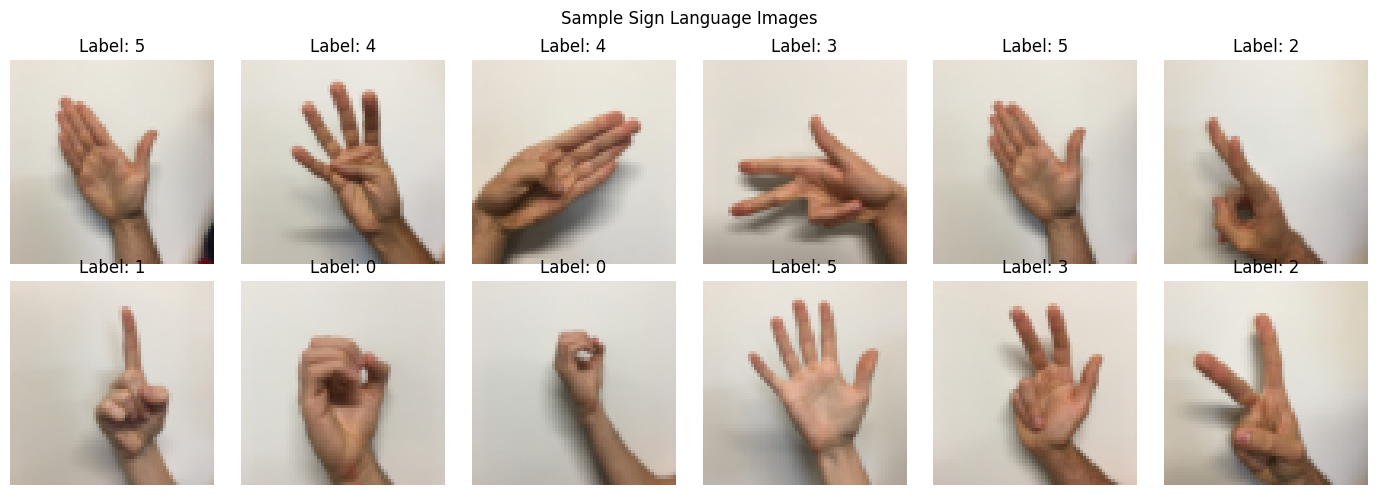

Train: (96, 64, 64, 3) (96,)
Test : (24, 64, 64, 3) (24,)


In [4]:
file_path = r"/content/test_signs.h5"   # <-- change this path if needed

with h5py.File(file_path, "r") as f:
    print("Keys in file:", list(f.keys()))
    X = np.array(f["test_set_x"])
    y = np.array(f["test_set_y"])
    classes = np.array(f["list_classes"])

print("Images:", X.shape, " Labels:", y.shape, " Classes:", classes)

# Look at some sample images
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, idx in zip(axes.flat, np.random.choice(len(X), 12, replace=False)):
    ax.imshow(X[idx])
    ax.set_title(f"Label: {y[idx]}")
    ax.axis("off")
plt.suptitle("Sample Sign Language Images")
plt.tight_layout()
plt.show()

# 80:20 split (stratified, so every class appears in both sets)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, y_train.shape)
print("Test :", X_test.shape, y_test.shape)

## 3. Pre-processing

LeNet-5 expects a **32x32 grayscale** image, so we:
1. Convert RGB to grayscale
2. Resize 64x64 to 32x32
3. Scale pixel values from 0-255 to 0-1
4. Make shape `(N, 1, 32, 32)` (PyTorch wants channels first)

In [5]:
def preprocess_images(images):
    out = []
    for img in images:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        out.append(cv2.resize(gray, (32, 32)))
    return np.array(out)

X_train_g = preprocess_images(X_train) / 255.0
X_test_g  = preprocess_images(X_test) / 255.0

X_train_t = torch.tensor(np.expand_dims(X_train_g, 1), dtype=torch.float32)
X_test_t  = torch.tensor(np.expand_dims(X_test_g, 1),  dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)
y_test_t  = torch.tensor(y_test,  dtype=torch.long)


class SignDataset(Dataset):
    def __init__(self, X, Y):
        self.X, self.Y = X, Y
    def __len__(self):
        return len(self.Y)
    def __getitem__(self, idx):
        return self.X[idx], self.Y[idx]


print("X_train:", X_train_t.shape, " y_train:", y_train_t.shape)
print("X_test :", X_test_t.shape,  " y_test :", y_test_t.shape)

X_train: torch.Size([96, 1, 32, 32])  y_train: torch.Size([96])
X_test : torch.Size([24, 1, 32, 32])  y_test : torch.Size([24])


## 4. Model 1: Original ConvNet (from the old notebook)

`CONV(8, 4x4) -> ReLU -> MaxPool(8) -> CONV(16, 2x2) -> ReLU -> MaxPool(4) -> FC(6)`

This is the same network as before. It is very small (only about 800 parameters).

In [6]:
class ConvNet(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 8, kernel_size=4, stride=1, padding=1)   # 32x32 -> 31x31
        self.pool1 = nn.MaxPool2d(kernel_size=8, stride=8)                 # 31x31 -> 3x3
        self.conv2 = nn.Conv2d(8, 16, kernel_size=2, stride=1, padding=1)  # 3x3   -> 4x4
        self.pool2 = nn.MaxPool2d(kernel_size=4, stride=4)                 # 4x4   -> 1x1
        self.fc = nn.Linear(16, num_classes)                               # 16*1*1 = 16

    def forward(self, x):
        x = self.pool1(F.relu(self.conv1(x)))
        x = self.pool2(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1)
        return self.fc(x)

## 5. Model 2: LeNet-5

The classic LeNet-5 for a 32x32 grayscale input:

| Layer | Details | Output shape |
|---|---|---|
| Input | grayscale image | 1 x 32 x 32 |
| C1 | Conv, 6 filters, 5x5 | 6 x 28 x 28 |
| S2 | Average pool 2x2 | 6 x 14 x 14 |
| C3 | Conv, 16 filters, 5x5 | 16 x 10 x 10 |
| S4 | Average pool 2x2 | 16 x 5 x 5 |
| Flatten | 16 x 5 x 5 | 400 |
| F5 | Fully connected | 120 |
| F6 | Fully connected | 84 |
| Output | Fully connected | 6 (sign classes) |

The original LeNet-5 uses `tanh` activation and average pooling, so we use the same here.

In [7]:
class LeNet5(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()
        self.c1 = nn.Conv2d(1, 6, kernel_size=5)       # 32x32 -> 28x28
        self.s2 = nn.AvgPool2d(kernel_size=2, stride=2) # 28x28 -> 14x14
        self.c3 = nn.Conv2d(6, 16, kernel_size=5)      # 14x14 -> 10x10
        self.s4 = nn.AvgPool2d(kernel_size=2, stride=2) # 10x10 -> 5x5
        self.f5 = nn.Linear(16 * 5 * 5, 120)
        self.f6 = nn.Linear(120, 84)
        self.out = nn.Linear(84, num_classes)

    def forward(self, x):
        x = self.s2(torch.tanh(self.c1(x)))
        x = self.s4(torch.tanh(self.c3(x)))
        x = torch.flatten(x, 1)
        x = torch.tanh(self.f5(x))
        x = torch.tanh(self.f6(x))
        return self.out(x)


def count_params(m):
    return sum(p.numel() for p in m.parameters())

print("ConvNet parameters:", count_params(ConvNet()))
print("LeNet-5 parameters:", count_params(LeNet5()))

# Quick shape check
dummy = torch.randn(2, 1, 32, 32)
print("ConvNet output:", ConvNet()(dummy).shape)
print("LeNet-5 output:", LeNet5()(dummy).shape)

ConvNet parameters: 766
LeNet-5 parameters: 61366
ConvNet output: torch.Size([2, 6])
LeNet-5 output: torch.Size([2, 6])


## 6. Training function

One function trains **any** model. After every epoch it records:
- training loss and training accuracy
- test loss and test accuracy

so we can plot them later. (Batch size 64, Adam optimizer, CrossEntropy loss, same as the original notebook.)

In [8]:
def evaluate(model, X, Y, criterion):
    model.eval()
    with torch.no_grad():
        logits = model(X.to(device))
        loss = criterion(logits, Y.to(device)).item()
        acc = (logits.argmax(dim=1).cpu() == Y).float().mean().item()
    return loss, acc


def train_model(model, learning_rate, num_epochs, minibatch_size=64, print_every=50):
    torch.manual_seed(1)
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    loader = DataLoader(SignDataset(X_train_t, y_train_t),
                        batch_size=minibatch_size, shuffle=True)

    hist = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}

    for epoch in range(num_epochs):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()

        # Measure after each epoch
        tr_loss, tr_acc = evaluate(model, X_train_t, y_train_t, criterion)
        te_loss, te_acc = evaluate(model, X_test_t,  y_test_t,  criterion)
        hist["train_loss"].append(tr_loss)
        hist["train_acc"].append(tr_acc)
        hist["test_loss"].append(te_loss)
        hist["test_acc"].append(te_acc)

        if epoch % print_every == 0 or epoch == num_epochs - 1:
            print(f"Epoch {epoch:4d} | train loss {tr_loss:.4f}, acc {tr_acc:.3f} "
                  f"| test loss {te_loss:.4f}, acc {te_acc:.3f}")
    return hist

## 7. Train the original ConvNet (lr = 0.0001, epochs = 1000)

In [9]:
torch.manual_seed(1)
convnet = ConvNet(num_classes=6)
hist_cnn = train_model(convnet, learning_rate=0.0001, num_epochs=1000)

Epoch    0 | train loss 1.8118, acc 0.167 | test loss 1.8093, acc 0.167
Epoch   50 | train loss 1.8013, acc 0.167 | test loss 1.7993, acc 0.167
Epoch  100 | train loss 1.7956, acc 0.167 | test loss 1.7943, acc 0.167
Epoch  150 | train loss 1.7915, acc 0.167 | test loss 1.7907, acc 0.167
Epoch  200 | train loss 1.7882, acc 0.188 | test loss 1.7884, acc 0.167
Epoch  250 | train loss 1.7857, acc 0.177 | test loss 1.7871, acc 0.167
Epoch  300 | train loss 1.7831, acc 0.177 | test loss 1.7854, acc 0.208
Epoch  350 | train loss 1.7810, acc 0.229 | test loss 1.7841, acc 0.208
Epoch  400 | train loss 1.7786, acc 0.281 | test loss 1.7826, acc 0.208
Epoch  450 | train loss 1.7762, acc 0.271 | test loss 1.7811, acc 0.292
Epoch  500 | train loss 1.7736, acc 0.250 | test loss 1.7794, acc 0.250
Epoch  550 | train loss 1.7708, acc 0.354 | test loss 1.7774, acc 0.292
Epoch  600 | train loss 1.7674, acc 0.333 | test loss 1.7748, acc 0.292
Epoch  650 | train loss 1.7638, acc 0.385 | test loss 1.7725, ac

## 8. Train LeNet-5 (lr = 0.001, epochs = 500)

In [10]:
torch.manual_seed(1)
lenet = LeNet5(num_classes=6)
hist_lenet = train_model(lenet, learning_rate=0.001, num_epochs=500)

Epoch    0 | train loss 1.7859, acc 0.167 | test loss 1.7893, acc 0.167
Epoch   50 | train loss 0.4854, acc 0.875 | test loss 2.2837, acc 0.458
Epoch  100 | train loss 0.1025, acc 0.979 | test loss 3.2363, acc 0.375
Epoch  150 | train loss 0.0215, acc 1.000 | test loss 3.8073, acc 0.375
Epoch  200 | train loss 0.0090, acc 1.000 | test loss 4.1442, acc 0.375
Epoch  250 | train loss 0.0052, acc 1.000 | test loss 4.3662, acc 0.375
Epoch  300 | train loss 0.0034, acc 1.000 | test loss 4.5129, acc 0.375
Epoch  350 | train loss 0.0024, acc 1.000 | test loss 4.6493, acc 0.375
Epoch  400 | train loss 0.0019, acc 1.000 | test loss 4.7441, acc 0.375
Epoch  450 | train loss 0.0015, acc 1.000 | test loss 4.8262, acc 0.375
Epoch  499 | train loss 0.0012, acc 1.000 | test loss 4.9116, acc 0.375


## 9. Compare the two models

Left: **loss**. Right: **accuracy**. Both models are drawn in the same figure.
Solid lines = train, dashed lines = test.
The x-axis is the epoch number (ConvNet runs for 1000 epochs, LeNet for 500).

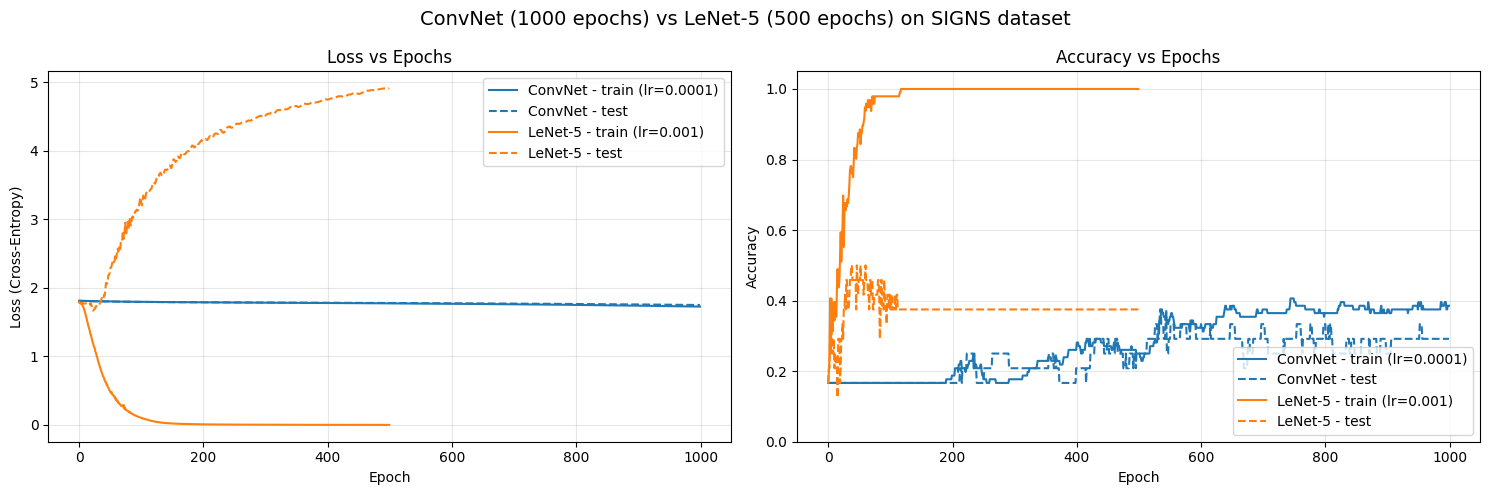

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# ---- Loss ----
ax1.plot(hist_cnn["train_loss"],   color="tab:blue",   label="ConvNet - train (lr=0.0001)")
ax1.plot(hist_cnn["test_loss"],    color="tab:blue",   linestyle="--", label="ConvNet - test")
ax1.plot(hist_lenet["train_loss"], color="tab:orange", label="LeNet-5 - train (lr=0.001)")
ax1.plot(hist_lenet["test_loss"],  color="tab:orange", linestyle="--", label="LeNet-5 - test")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss (Cross-Entropy)")
ax1.set_title("Loss vs Epochs")
ax1.grid(alpha=0.3)
ax1.legend()

# ---- Accuracy ----
ax2.plot(hist_cnn["train_acc"],   color="tab:blue",   label="ConvNet - train (lr=0.0001)")
ax2.plot(hist_cnn["test_acc"],    color="tab:blue",   linestyle="--", label="ConvNet - test")
ax2.plot(hist_lenet["train_acc"], color="tab:orange", label="LeNet-5 - train (lr=0.001)")
ax2.plot(hist_lenet["test_acc"],  color="tab:orange", linestyle="--", label="LeNet-5 - test")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy")
ax2.set_ylim(0, 1.05)
ax2.set_title("Accuracy vs Epochs")
ax2.grid(alpha=0.3)
ax2.legend(loc="lower right")

plt.suptitle("ConvNet (1000 epochs) vs LeNet-5 (500 epochs) on SIGNS dataset", fontsize=14)
plt.tight_layout()
plt.show()

## 10. Final accuracy table

In [12]:
import pandas as pd

summary = pd.DataFrame({
    "Model":          ["Original ConvNet", "LeNet-5"],
    "Learning rate":  [0.0001, 0.001],
    "Epochs":         [1000, 500],
    "Parameters":     [count_params(convnet), count_params(lenet)],
    "Train accuracy": [hist_cnn["train_acc"][-1],  hist_lenet["train_acc"][-1]],
    "Test accuracy":  [hist_cnn["test_acc"][-1],   hist_lenet["test_acc"][-1]],
    "Final train loss": [hist_cnn["train_loss"][-1], hist_lenet["train_loss"][-1]],
    "Final test loss":  [hist_cnn["test_loss"][-1],  hist_lenet["test_loss"][-1]],
})
display(summary.round(4))

best = summary.loc[summary["Test accuracy"].idxmax(), "Model"]
print(f"\nHigher test accuracy: {best}")

,Model,Learning rate,Epochs,Parameters,Train accuracy,Test accuracy,Final train loss,Final test loss
0,Original ConvNet,0.0001,1000,766,0.3854,0.2917,1.7261,1.7496
1,LeNet-5,0.0010,500,61366,1.0000,0.3750,0.0012,4.9116



Higher test accuracy: LeNet-5


## 11. Observations (fill in after running)

- Which model reaches high accuracy faster?

LeNet-5 by a wide margin. Its training accuracy was already about 0.875 by epoch 50 and about 0.98 by epoch 100, reaching 1.000 by epoch 150. The original ConvNet barely moved over 1000 epochs. It stayed near chance (about 0.167, i.e. 1 in 6 classes) until roughly epoch 200 and only reached 0.385 train accuracy at epoch 999. It was still improving slowly when training stopped, so it is clearly under-trained.

- Which model has the lower final loss?

On the training set, LeNet-5 (0.0012 vs 1.7261 for the ConvNet). On the test set the picture reverses: the ConvNet’s final test loss is 1.7496, while LeNet-5’s is 4.9116. The ConvNet’s loss is only slightly below the starting value of about 1.79 (ln 6), meaning it has learned very little. LeNet-5’s very low training loss does not carry over to unseen data.

- Is there a big gap between train and test accuracy (overfitting)?

Yes, for LeNet-5. It reaches 100% train accuracy but only 37.5% test accuracy, and its test loss rises steadily from epoch ~50 onward (2.28 → 4.91) while the train loss keeps falling. This is classic overfitting: the model memorises the 96 training images. The ConvNet shows almost no gap (38.5% train vs 29.2% test), but that is because it is underfitting, not because it generalises well. With only 24 test images, one image changes accuracy by about 4.2 percentage points, so the 37.5% vs 29.2% difference (2 images) is not statistically meaningful and could change from run to run.

LeNet-5 has many more parameters and a 10x higher learning rate, so it is expected to learn faster.
Confirmed. LeNet-5 has 61,366 parameters versus 766 for the ConvNet (about 80x more), and it used lr = 0.001 versus 0.0001. Together these let it fit the training data within ~150 epochs, while the tiny ConvNet with its aggressive pooling (8x8 then 4x4, collapsing the features to 16 values) and low learning rate lacks the capacity and step size to learn much in 1000 epochs. However, the extra capacity combined with a very small dataset (96 images) is what causes LeNet-5 to overfit.

Conclusion: LeNet-5 is better at learning the training data and slightly ahead on test accuracy, but neither model generalises well on this dataset. Improvements to try: data augmentation (flips, small rotations or shifts), dropout or weight decay, early stopping (LeNet-5’s best test accuracy was around epoch 50), more training data, and a higher learning rate or less aggressive pooling for the ConvNet.